# Validation RMSE Analysis by Input Value

This notebook evaluates the full-feature LightGBM model using the best parameters from `exp_2`. It identifies the input values for which the validation predictions have the highest RMSE.

Groups with fewer than 30 validation records are excluded from the rankings, because their RMSE is too unstable to interpret reliably.

In [9]:
import sys
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# Locate preprocessing.py in local and remote Colab project layouts.
module_dirs = []
for parent in [Path.cwd(), *Path.cwd().parents]:
    module_dirs.extend([parent, parent / 'exploration' / 'metul'])
for root in [Path('/content'), Path('/content/drive/MyDrive')]:
    module_dirs.extend([root, root / 'KDDM-project', root / 'KDDM-project' / 'exploration' / 'metul'])
    if root.exists():
        try:
            module_dirs.extend(path.parent for path in root.rglob('preprocessing.py'))
        except (OSError, PermissionError):
            pass

for module_dir in module_dirs:
    if (module_dir / 'preprocessing.py').exists():
        sys.path.insert(0, str(module_dir))
        break

import importlib
import preprocessing
importlib.reload(preprocessing)
from preprocessing import load_datasets, preprocess_frame

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1200)

In [10]:
data_dir, datasets = load_datasets()
joined_df = preprocess_frame(datasets['train'], datasets)

TARGET = 'MONTHLY_RENT'
EXCLUDED_COLUMNS = [TARGET, 'RENT_APPROVAL_DATE', 'FEE', 'FURNISHED']
FEATURE_COLUMNS = [
    column for column in joined_df.columns
    if column not in EXCLUDED_COLUMNS
]

X = joined_df[FEATURE_COLUMNS].copy()
y = joined_df[TARGET].copy()
categorical_columns = X.select_dtypes(include=['object', 'string']).columns.tolist()
for column in categorical_columns:
    X[column] = X[column].astype('category')

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f'Data directory: {data_dir.resolve()}')
print(f'Training rows: {len(X_train):,} | Validation rows: {len(X_valid):,}')
print(f'Features: {len(FEATURE_COLUMNS)}')

Data directory: /Users/metul/Desktop/KDDM-project/data
Training rows: 120,000 | Validation rows: 30,000
Features: 30


## Time Series Analysis

Average monthly rent is plotted by rental approval month and year.

In [ ]:
monthly_avg_rent = (
    joined_df.groupby('RENT_APPROVAL_DATE', as_index=False)
    .agg(
        average_monthly_rent=('MONTHLY_RENT', 'mean'),
        coe_quota_premium_mean=('coe_quota_premium_mean', 'mean'),
    )
)
monthly_avg_rent['approval_period'] = pd.to_datetime(
    monthly_avg_rent['RENT_APPROVAL_DATE'] + '-01'
)
monthly_avg_rent = monthly_avg_rent.sort_values('approval_period')

# Monthly close-price indices for selected major Singapore-listed stocks.
STOCK_SYMBOLS = {
    'D05.SI': 'DBS Group',
    'O39.SI': 'OCBC Bank',
    'U11.SI': 'UOB',
    'Z74.SI': 'Singtel',
    'C6L.SI': 'Singapore Airlines',
    'BN4.SI': 'Keppel',
}
stock_prices = datasets['stock'].copy()
stock_prices['DATE'] = pd.to_datetime(stock_prices['DATE'])
stock_prices['approval_period'] = stock_prices['DATE'].dt.to_period('M').dt.to_timestamp()
monthly_stock_prices = (
    stock_prices[stock_prices['SYMBOL'].isin(STOCK_SYMBOLS)]
    .groupby(['approval_period', 'SYMBOL'], as_index=False)['CLOSE']
    .mean()
    .rename(columns={'CLOSE': 'monthly_average_close'})
    .sort_values(['SYMBOL', 'approval_period'])
)
monthly_stock_prices['close_price_index'] = (
    monthly_stock_prices['monthly_average_close']
    / monthly_stock_prices.groupby('SYMBOL')['monthly_average_close'].transform('first')
    * 100
)

fig, (ax_rent, ax_stock) = plt.subplots(
    2, 1, figsize=(14, 9), dpi=120, sharex=True,
    gridspec_kw={'height_ratios': [3, 2]},
)
rent_line = ax_rent.plot(
    monthly_avg_rent['approval_period'],
    monthly_avg_rent['average_monthly_rent'],
    marker='o', markersize=3.5, linewidth=2, color='#2b6cb0',
    label='Average monthly rent',
)
ax_rent.set_title('Average Monthly Rent and Mean COE Premium by Approval Month', fontsize=14, fontweight='bold', pad=12)
ax_rent.set_ylabel('Average monthly rent', color='#2b6cb0')
ax_rent.tick_params(axis='y', labelcolor='#2b6cb0')
ax_rent.grid(True, linestyle=':', alpha=0.5)

ax_coe = ax_rent.twinx()
coe_line = ax_coe.plot(
    monthly_avg_rent['approval_period'],
    monthly_avg_rent['coe_quota_premium_mean'],
    marker='s', markersize=3.5, linewidth=2, color='#c0392b',
    label='Mean COE quota premium',
)
ax_coe.set_ylabel('Mean COE quota premium', color='#c0392b')
ax_coe.tick_params(axis='y', labelcolor='#c0392b')
ax_rent.legend(rent_line + coe_line, [line.get_label() for line in rent_line + coe_line], loc='upper left')

for symbol, stock_name in STOCK_SYMBOLS.items():
    stock_data = monthly_stock_prices[monthly_stock_prices['SYMBOL'] == symbol]
    ax_stock.plot(
        stock_data['approval_period'], stock_data['close_price_index'],
        linewidth=1.8, marker='o', markersize=2.5, label=stock_name,
    )
ax_stock.axhline(100, color='black', linewidth=0.8, linestyle='--', alpha=0.7)
ax_stock.set_title('Monthly Stock Close Prices Indexed to First Month = 100', fontsize=12, fontweight='bold', pad=10)
ax_stock.set_xlabel('Approval month and year')
ax_stock.set_ylabel('Indexed close price')
ax_stock.grid(True, linestyle=':', alpha=0.5)
ax_stock.legend(loc='upper left', ncol=3, fontsize=8)
fig.autofmt_xdate()
plt.tight_layout()
plt.show()

display(monthly_avg_rent[[
    'RENT_APPROVAL_DATE', 'average_monthly_rent', 'coe_quota_premium_mean',
]])

## Train with the best `exp_2` parameters

These are the specified best parameters: `num_leaves=18`, `num_iterations=938`, `learning_rate=0.036935`, `max_depth=4`, `min_gain_to_split=0.716468`, and `min_data_in_leaf=30`.

In [11]:
PARAMETER_COLUMNS = [
    'num_leaves', 'num_iterations', 'learning_rate',
    'max_depth', 'min_gain_to_split', 'min_data_in_leaf',
]
parameter_candidates = []
for parent in [Path.cwd(), *Path.cwd().parents]:
    parameter_candidates.extend([
        parent / 'exp_2_best_params.csv',
        parent / 'exploration' / 'metul' / 'exp_2_best_params.csv',
    ])
best_params_file = next((path for path in parameter_candidates if path.exists()), None)
if best_params_file is None:
    raise FileNotFoundError(
        'Could not find exp_2_best_params.csv. Run the Optuna cell in exp_2 first.'
    )

best_params_row = pd.read_csv(best_params_file).iloc[0]
BEST_PARAMS = {column: best_params_row[column] for column in PARAMETER_COLUMNS}
BEST_PARAMS['num_leaves'] = int(BEST_PARAMS['num_leaves'])
BEST_PARAMS['num_iterations'] = int(BEST_PARAMS['num_iterations'])
BEST_PARAMS['max_depth'] = int(BEST_PARAMS['max_depth'])
BEST_PARAMS['min_data_in_leaf'] = int(BEST_PARAMS['min_data_in_leaf'])
print(f'Loaded best parameters from: {best_params_file.resolve()}')

model = lgb.LGBMRegressor(
    objective='regression',
    random_state=42,
    verbosity=-1,
    n_jobs=-1,
    **BEST_PARAMS,
)
model.fit(X_train, y_train, categorical_feature=categorical_columns)

validation_predictions = model.predict(X_valid)
overall_metrics = pd.DataFrame([{
    'RMSE': mean_squared_error(y_valid, validation_predictions) ** 0.5,
    'MAE': mean_absolute_error(y_valid, validation_predictions),
    'R2': r2_score(y_valid, validation_predictions),
}])
display(overall_metrics.style.format('{:.3f}'))

Loaded best parameters from: /Users/metul/Desktop/KDDM-project/exploration/metul/exp_2_best_params.csv


,RMSE,MAE,R2
0,478.874,360.272,0.592


## Validation RMSE by feature value

For each feature, RMSE is calculated separately for each input value in the held-out validation data. The table ranks the least-performing values first.

In [ ]:
# Attach actual values, predictions, and errors to the validation feature rows.
validation_results = joined_df.loc[X_valid.index].copy()
validation_results['actual_rent'] = y_valid
validation_results['predicted_rent'] = validation_predictions
validation_results['residual'] = validation_results['actual_rent'] - validation_results['predicted_rent']
validation_results['squared_error'] = validation_results['residual'] ** 2
validation_results['absolute_error'] = validation_results['residual'].abs()

# Group continuous proximity values into interpretable 0.25 km ranges.
for feature in ['mrt_dist_nearest_km', 'mall_dist_nearest_km', 'school_dist_nearest_km']:
    upper_bound = np.ceil(validation_results[feature].max() / 0.25) * 0.25
    bins = np.arange(0, upper_bound + 0.25, 0.25)
    validation_results[f'{feature}_bin'] = pd.cut(
        validation_results[feature], bins=bins, include_lowest=True, right=False
    )

MIN_GROUP_SIZE = 30
TOP_N = 10

def rmse_by_feature_value(frame, feature, min_group_size=MIN_GROUP_SIZE):
    grouped = (
        frame.groupby(feature, dropna=False)
        .agg(
            validation_rows=('squared_error', 'size'),
            rmse=('squared_error', lambda values: np.sqrt(values.mean())),
            mae=('absolute_error', 'mean'),
            mean_residual=('residual', 'mean'),
            mean_actual_rent=('actual_rent', 'mean'),
            mean_predicted_rent=('predicted_rent', 'mean'),
        )
        .reset_index()
    )
    return (
        grouped[grouped['validation_rows'] >= min_group_size]
        .sort_values(['rmse', 'validation_rows'], ascending=[False, False])
        .reset_index(drop=True)
    )

# Area refers to floor area here. Planning-area data is not part of the current joined dataframe.
ANALYSIS_FEATURES = [
    'REGION', 'TOWN', 'BLOCK', 'STREET', 'FLAT_TYPE', 'FLAT_MODEL',
    'FLOOR_AREA_SQM', 'approval_year', 'approval_month',
    'LEASE_COMMENCE_DATE', 'lease_age', 'MAX_FLOOR', 'YEAR_COMPLETED',
    'flat_type_num', 'mrt_dist_nearest_km_bin',
    'mall_dist_nearest_km_bin', 'school_dist_nearest_km_bin',
]
ANALYSIS_FEATURES = [
    feature for feature in ANALYSIS_FEATURES
    if feature in validation_results.columns
]

rmse_tables = {
    feature: rmse_by_feature_value(validation_results, feature)
    for feature in ANALYSIS_FEATURES
}

worst_value_summary = pd.concat([
    table.head(1).assign(feature=feature)
    for feature, table in rmse_tables.items()
    if not table.empty
], ignore_index=True).sort_values('rmse', ascending=False)

display(worst_value_summary[[
    'feature', 'validation_rows', 'rmse', 'mae',
    'mean_residual', 'mean_actual_rent', 'mean_predicted_rent',
]].style.format({
    'rmse': '{:.2f}', 'mae': '{:.2f}', 'mean_residual': '{:+.2f}',
    'mean_actual_rent': '{:.2f}', 'mean_predicted_rent': '{:.2f}',
}))

,feature,validation_rows,rmse,mae,mean_residual,mean_actual_rent,mean_predicted_rent
12,YEAR_COMPLETED,35,1091.60,820.77,+63.55,3650.00,3586.45
5,FLAT_MODEL,39,946.83,716.37,-236.30,3405.90,3642.20
3,STREET,74,764.32,544.33,+6.66,2700.54,2693.88
2,BLOCK,34,698.67,451.85,-57.45,2747.06,2804.51
6,FLOOR_AREA_SQM,89,667.34,464.30,+13.07,2992.81,2979.74
7,approval_year,7286,603.47,482.66,-3.04,3036.56,3039.60
10,lease_age,446,598.48,437.13,-64.09,2681.59,2745.67
9,LEASE_COMMENCE_DATE,256,584.72,418.41,+15.51,2598.28,2582.77
4,FLAT_TYPE,1699,566.15,423.05,+43.84,3098.68,3054.84
13,flat_type_num,1699,566.15,423.05,+43.84,3098.68,3054.84


In [17]:
# Display the 10 least-performing eligible values for each feature.
for feature, table in rmse_tables.items():
    print(f'\nWorst {TOP_N} values for {feature} (minimum {MIN_GROUP_SIZE} validation rows):')
    display(table.head(TOP_N).style.format({
        'rmse': '{:.2f}', 'mae': '{:.2f}', 'mean_residual': '{:+.2f}',
        'mean_actual_rent': '{:.2f}', 'mean_predicted_rent': '{:.2f}',
    }))


Worst 10 values for REGION (minimum 30 validation rows):


,REGION,validation_rows,rmse,mae,mean_residual,mean_actual_rent,mean_predicted_rent
0,west region,6883,500.33,379.15,+3.56,2711.65,2708.10
1,central region,7613,493.71,368.08,+5.87,2856.52,2850.65
2,east region,4661,477.87,359.29,+11.23,2711.34,2700.11
3,north region,3787,461.01,355.19,+12.87,2586.72,2573.85
4,north-east region,7056,450.44,336.82,-4.11,2682.24,2686.35



Worst 10 values for TOWN (minimum 30 validation rows):


,TOWN,validation_rows,rmse,mae,mean_residual,mean_actual_rent,mean_predicted_rent
0,jurong west,2092,559.46,421.73,+24.70,2807.50,2782.80
1,bukit timah,82,529.49,396.92,+130.35,3106.95,2976.60
2,kallang/whampoa,1128,522.38,397.76,-17.54,2789.21,2806.75
3,bukit merah,1679,510.48,367.07,+18.53,3015.14,2996.61
4,central,429,509.01,382.38,-25.06,3122.71,3147.77
5,clementi,1045,503.75,376.08,-2.89,2792.60,2795.48
6,marine parade,312,500.45,362.69,-20.99,2676.99,2697.98
7,pasir ris,843,493.79,380.94,-0.48,2850.88,2851.36
8,queenstown,1271,488.29,364.78,+2.36,2927.59,2925.23
9,bishan,680,487.29,363.85,+37.33,3003.96,2966.63



Worst 10 values for BLOCK (minimum 30 validation rows):


...

,mrt_dist_nearest_km_bin,validation_rows,rmse,mae,mean_residual,mean_actual_rent,mean_predicted_rent
0,"[0.25, 0.5)",10238,485.00,362.69,-6.16,2763.25,2769.41
1,"[0.0, 0.25)",3375,484.74,364.85,+0.85,2835.52,2834.67
2,"[0.5, 0.75)",8712,477.37,360.77,+17.07,2718.55,2701.48
3,"[0.75, 1.0)",4779,476.19,357.24,+4.94,2636.82,2631.87
4,"[1.5, 1.75)",196,470.61,384.15,+43.94,2671.34,2627.40
5,"[1.25, 1.5)",537,468.73,362.20,+4.60,2563.06,2558.46
6,"[1.0, 1.25)",1868,466.96,353.87,+7.67,2640.09,2632.42
7,"[1.75, 2.0)",111,383.63,289.89,-64.17,2661.98,2726.15
8,"[2.0, 2.25)",119,362.97,280.31,+59.56,2791.76,2732.20
9,"[2.25, 2.5)",54,346.55,251.10,+59.13,2594.91,2535.78



Worst 10 values for mall_dist_nearest_km_bin (minimum 30 validation rows):


,mall_dist_nearest_km_bin,validation_rows,rmse,mae,mean_residual,mean_actual_rent,mean_predicted_rent
0,"[2.25, 2.5)",44,560.22,411.59,+148.55,3082.27,2933.72
1,"[2.0, 2.25)",290,512.52,383.83,+31.06,2644.00,2612.94
2,"[1.75, 2.0)",739,495.48,380.73,+0.28,2646.00,2645.72
3,"[1.5, 1.75)",1527,490.67,377.26,+14.42,2623.05,2608.62
4,"[0.5, 0.75)",7007,486.38,364.90,+13.70,2778.67,2764.97
5,"[1.0, 1.25)",3764,481.64,357.48,-1.42,2662.99,2664.42
6,"[1.25, 1.5)",2529,480.17,364.62,-15.43,2602.59,2618.01
7,"[0.75, 1.0)",5632,474.78,358.00,+4.00,2679.22,2675.22
8,"[0.25, 0.5)",6496,471.85,354.56,+0.80,2797.72,2796.92
9,"[0.0, 0.25)",1961,456.51,343.65,+12.05,2826.48,2814.43



Worst 10 values for school_dist_nearest_km_bin (minimum 30 validation rows):


,school_dist_nearest_km_bin,validation_rows,rmse,mae,mean_residual,mean_actual_rent,mean_predicted_rent
0,"[1.5, 1.75)",39,500.04,370.34,-17.45,2745.64,2763.09
1,"[0.5, 0.75)",3856,490.04,368.54,+18.96,2726.23,2707.27
2,"[0.25, 0.5)",13441,482.00,362.34,+2.55,2715.76,2713.21
3,"[0.0, 0.25)",11421,472.59,355.68,+4.12,2733.03,2728.90
4,"[0.75, 1.0)",805,467.52,356.62,-16.65,2693.71,2710.36
5,"[1.0, 1.25)",372,466.43,344.80,-28.13,2865.85,2893.99
6,"[1.25, 1.5)",46,446.06,381.51,+197.73,3257.17,3059.45


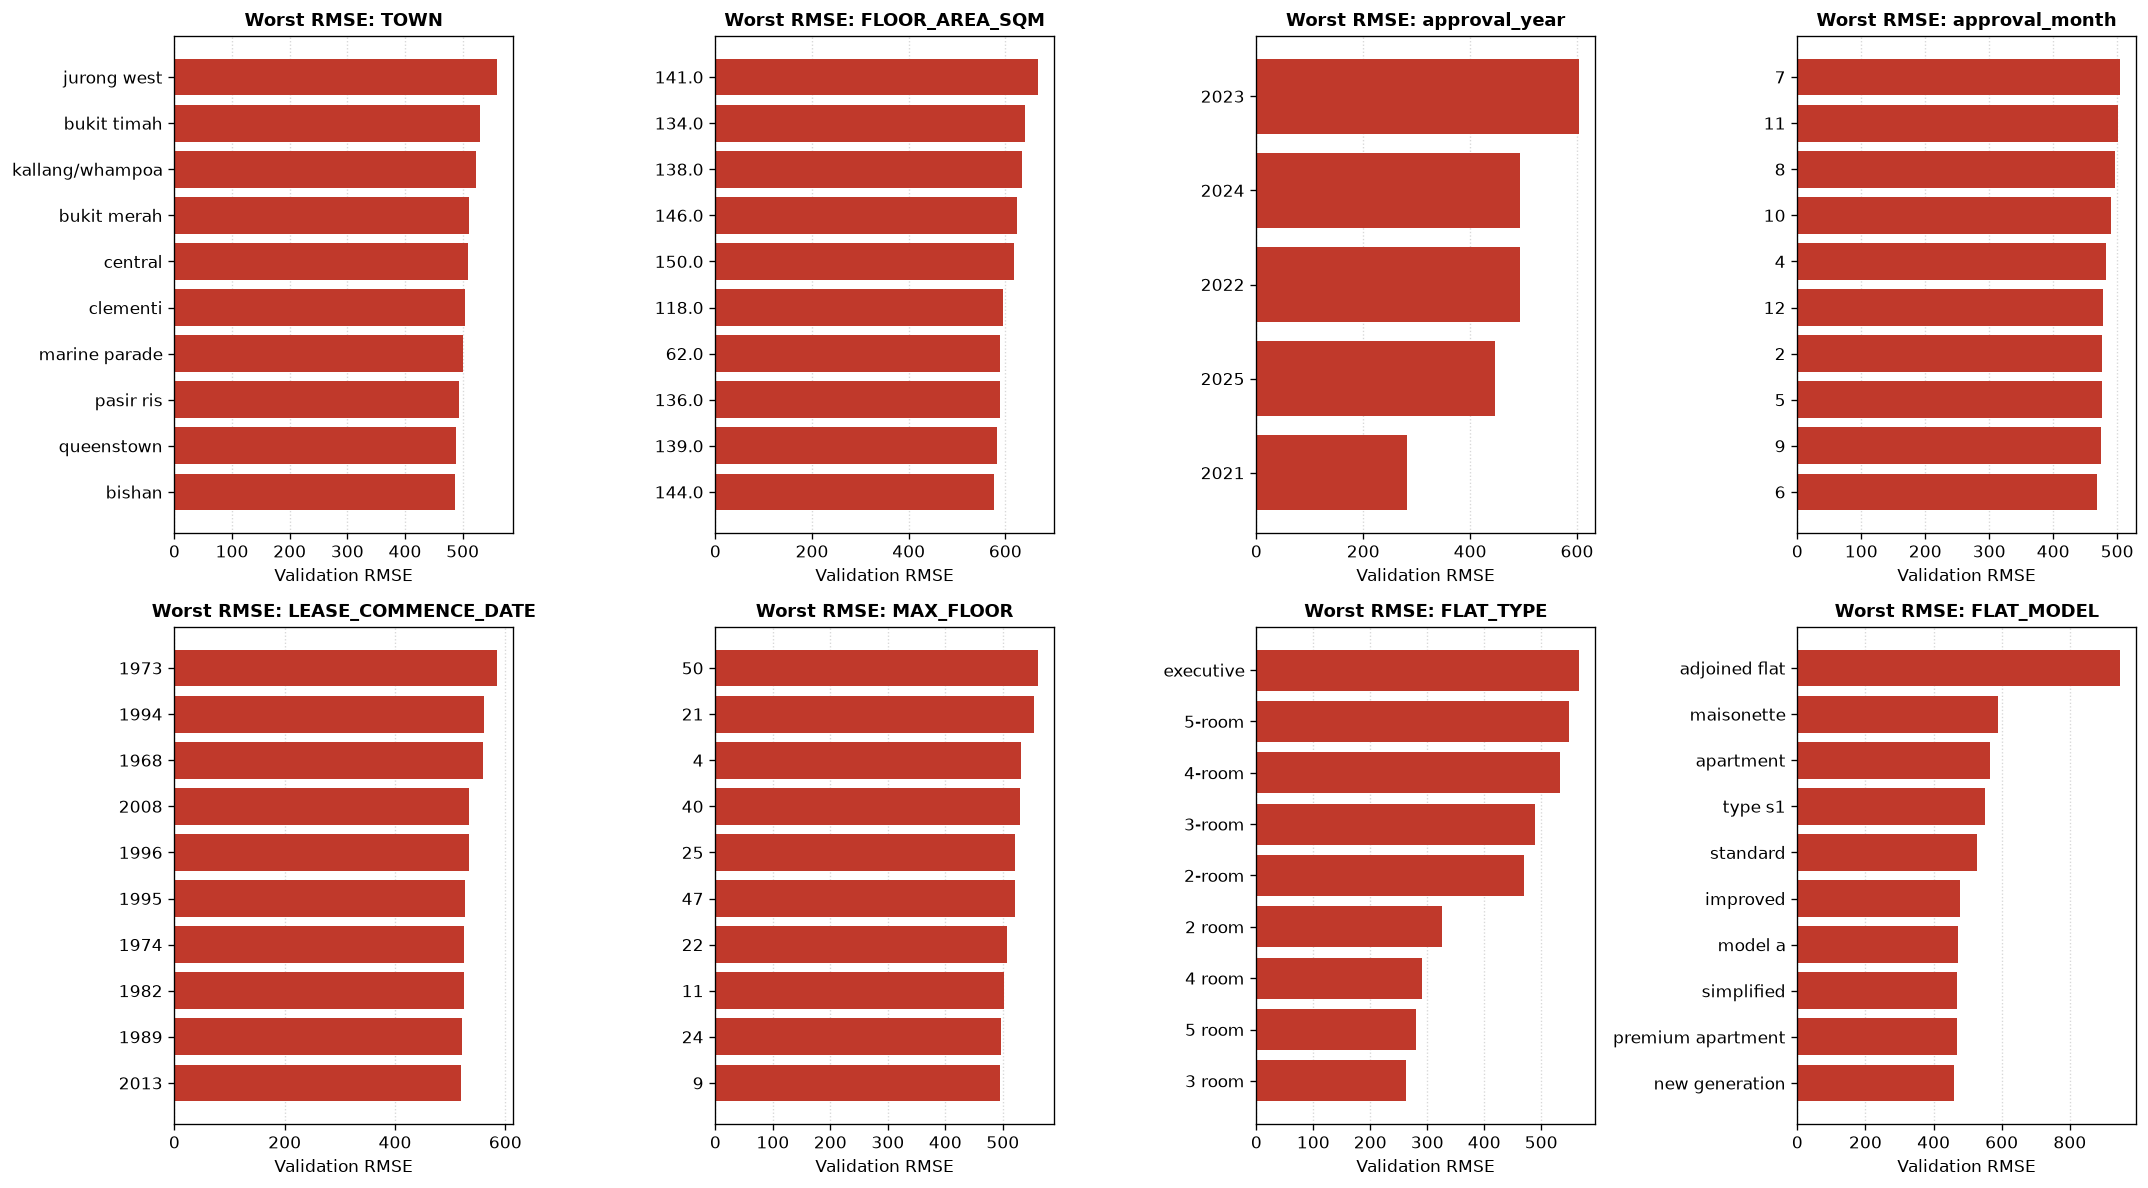

In [14]:
# Compact charts for the most interpretable grouped features.
PLOT_FEATURES = [
    'TOWN', 'FLOOR_AREA_SQM', 'approval_year', 'approval_month',
    'LEASE_COMMENCE_DATE', 'MAX_FLOOR', 'FLAT_TYPE', 'FLAT_MODEL',
]
plot_features = [feature for feature in PLOT_FEATURES if feature in rmse_tables]
fig, axes = plt.subplots(2, 4, figsize=(18, 10), dpi=120)

for ax, feature in zip(axes.flat, plot_features):
    plot_data = rmse_tables[feature].head(TOP_N).sort_values('rmse')
    ax.barh(plot_data[feature].astype(str), plot_data['rmse'], color='#c0392b')
    ax.set_title(f'Worst RMSE: {feature}', fontsize=11, fontweight='bold')
    ax.set_xlabel('Validation RMSE')
    ax.grid(axis='x', linestyle=':', alpha=0.5)
    ax.set_axisbelow(True)

for ax in axes.flat[len(plot_features):]:
    ax.axis('off')

plt.tight_layout()
plt.show()

## Residual errors against input features

Residual = actual rent − predicted rent. Values above zero are under-predictions; values below zero are over-predictions.

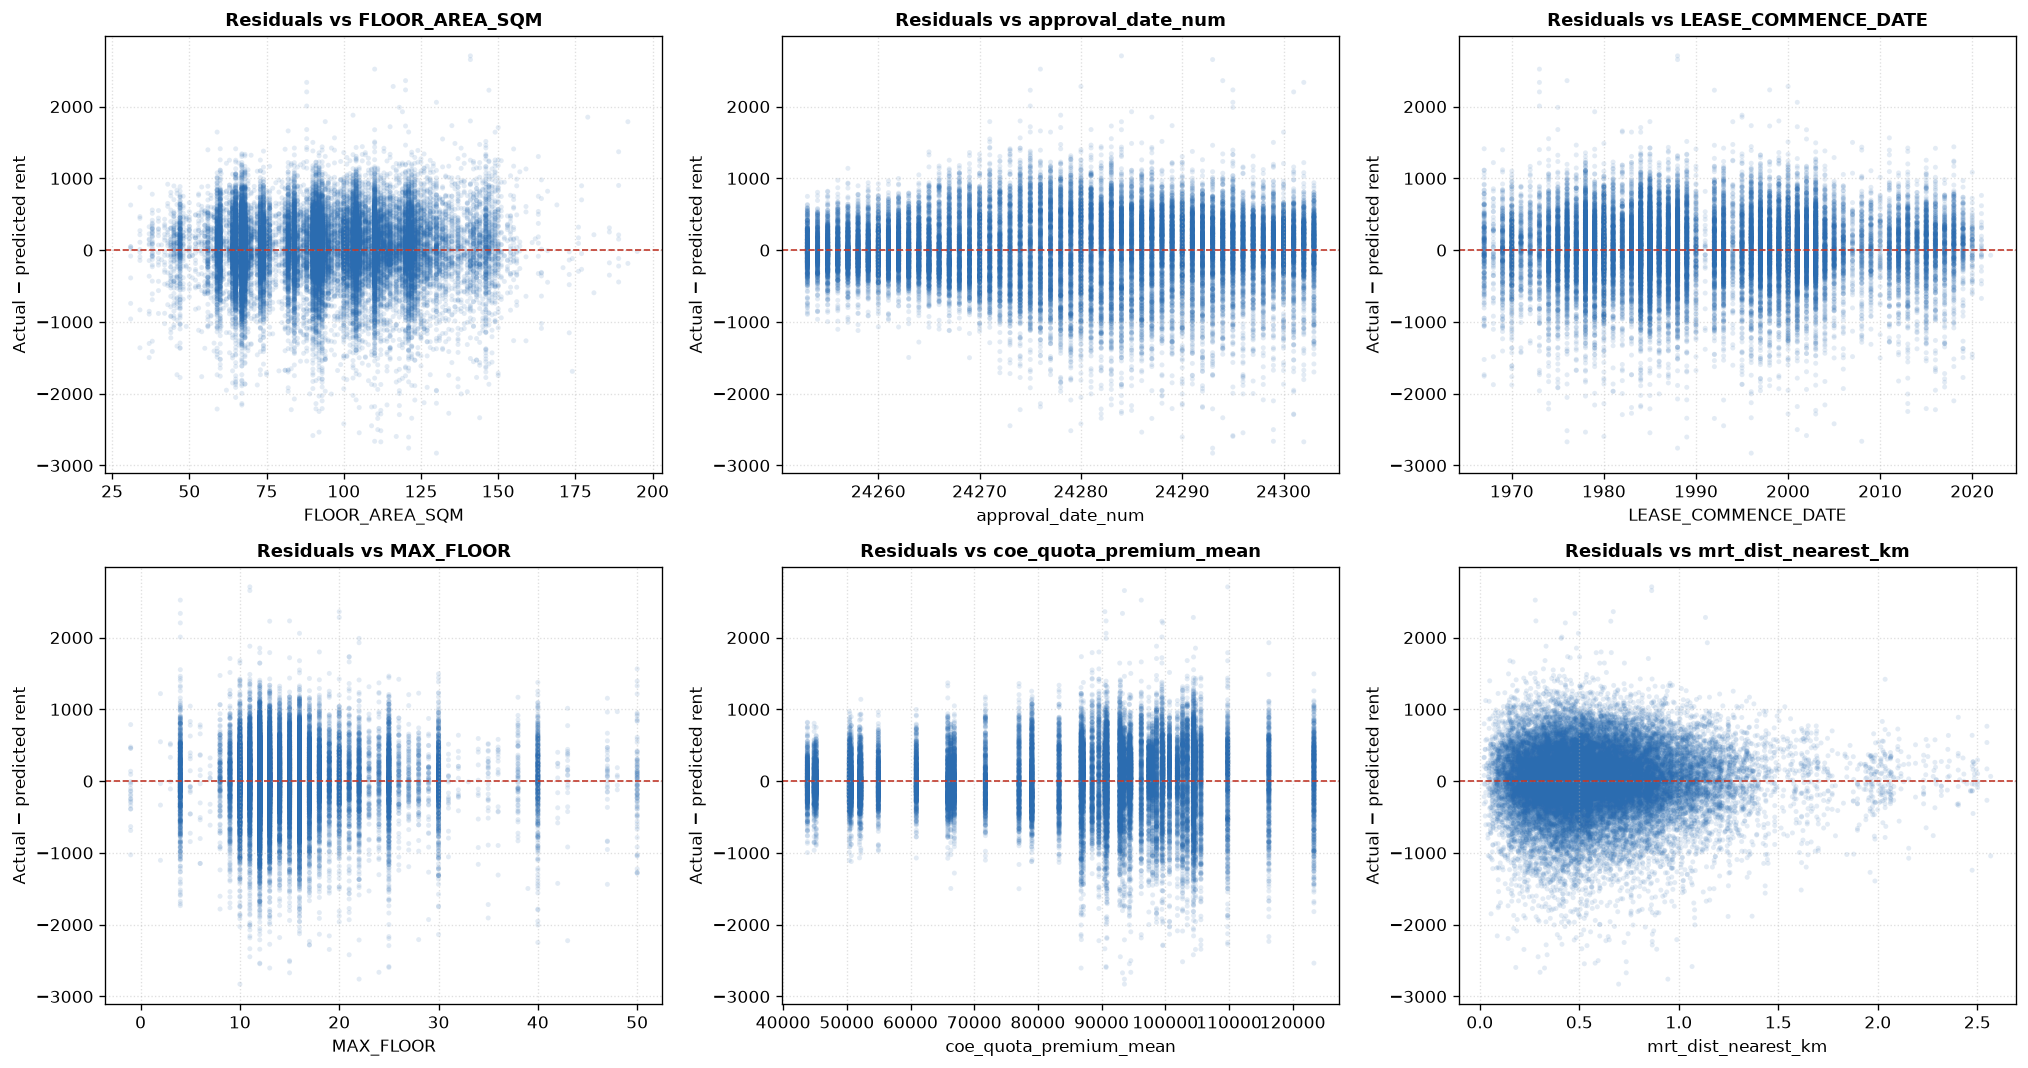

In [15]:
# Scatter plots for continuous and ordinal input features.
NUMERIC_RESIDUAL_FEATURES = [
    'FLOOR_AREA_SQM', 'approval_date_num', 'LEASE_COMMENCE_DATE',
    'MAX_FLOOR', 'coe_quota_premium_mean', 'mrt_dist_nearest_km',
]

fig, axes = plt.subplots(2, 3, figsize=(17, 9), dpi=120)
for ax, feature in zip(axes.flat, NUMERIC_RESIDUAL_FEATURES):
    plot_data = validation_results[[feature, 'residual']].dropna()
    ax.scatter(
        plot_data[feature], plot_data['residual'],
        s=9, alpha=0.13, color='#2b6cb0', edgecolors='none',
    )
    ax.axhline(0, color='#c0392b', linewidth=1.0, linestyle='--')
    ax.set_title(f'Residuals vs {feature}', fontsize=11, fontweight='bold')
    ax.set_xlabel(feature)
    ax.set_ylabel('Actual − predicted rent')
    ax.grid(linestyle=':', alpha=0.4)

plt.tight_layout()
plt.show()

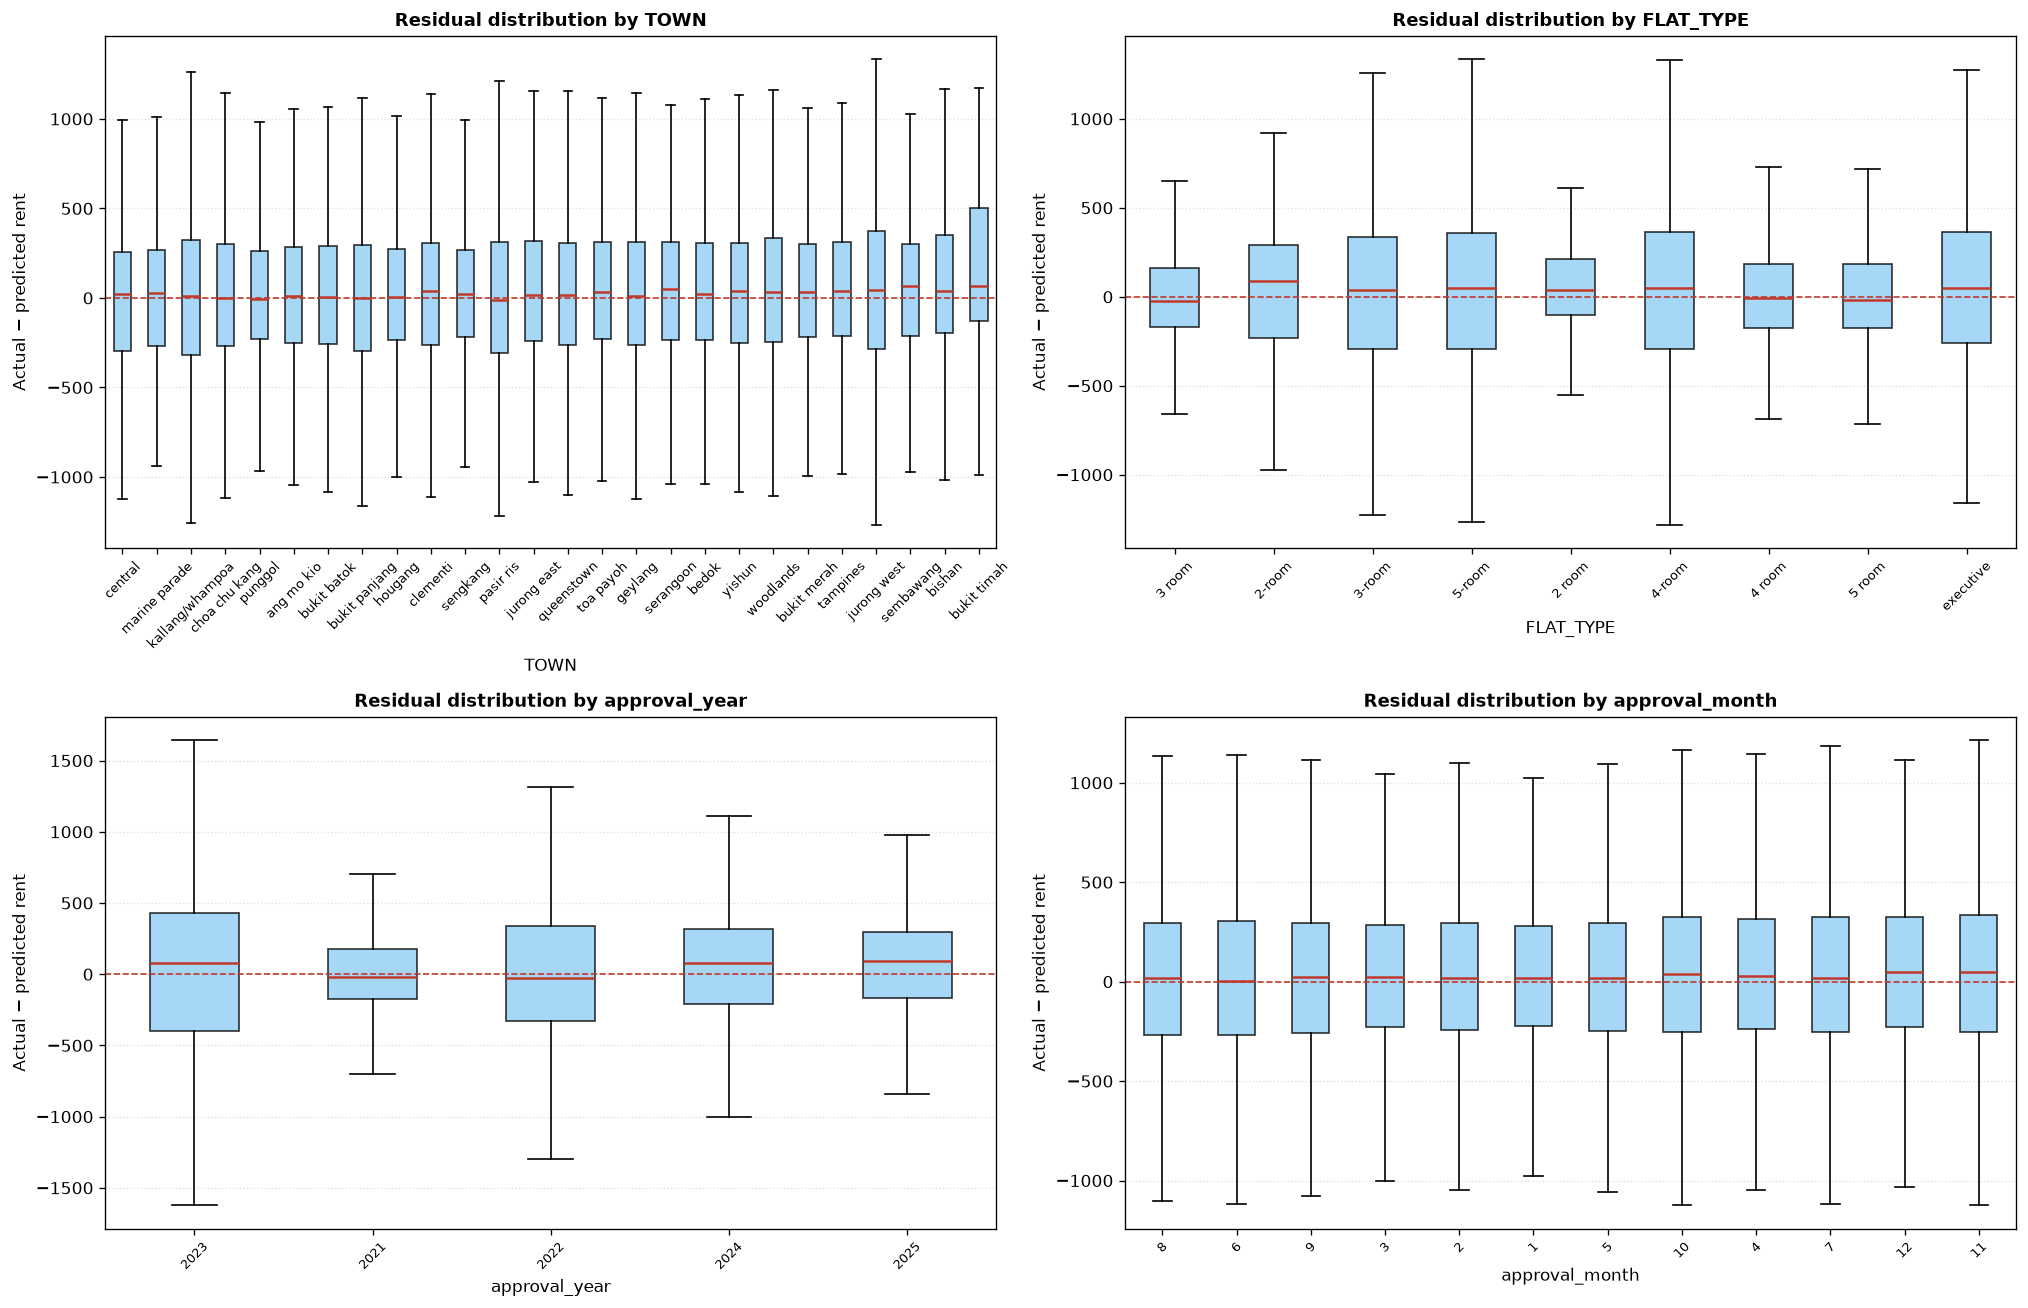

In [16]:
# Box plots for categorical and low-cardinality temporal features.
BOXPLOT_FEATURES = ['TOWN', 'FLAT_TYPE', 'approval_year', 'approval_month']
fig, axes = plt.subplots(2, 2, figsize=(17, 11), dpi=120)

for ax, feature in zip(axes.flat, BOXPLOT_FEATURES):
    grouped = validation_results.groupby(feature, dropna=False)['residual']
    groups = [
        (str(value), residuals.to_numpy())
        for value, residuals in grouped
        if len(residuals) >= MIN_GROUP_SIZE
    ]
    groups.sort(key=lambda item: item[1].mean())
    labels, values = zip(*groups)

    ax.boxplot(values, tick_labels=labels, showfliers=False, patch_artist=True,
               boxprops={'facecolor': '#90cdf4', 'alpha': 0.8},
               medianprops={'color': '#c0392b', 'linewidth': 1.5})
    ax.axhline(0, color='#c0392b', linewidth=1.0, linestyle='--')
    ax.set_title(f'Residual distribution by {feature}', fontsize=11, fontweight='bold')
    ax.set_xlabel(feature)
    ax.set_ylabel('Actual − predicted rent')
    ax.tick_params(axis='x', labelrotation=45, labelsize=8)
    ax.grid(axis='y', linestyle=':', alpha=0.4)

plt.tight_layout()
plt.show()